<a href="https://colab.research.google.com/github/ritika-adk/AI_Ml-BootCamp/blob/main/MNIST_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Implementation using PyTorch

## MNIST handwritten-digit classification

Experiments results are at the end -Ritika Adhikari

In this lesson, we will build a small **fully connected neural network** that recognizes handwritten digits from **0 to 9**.

MNIST is a dataset of grayscale handwritten-digit images.

- Each image is **28 pixels wide × 28 pixels high**.
- Each image belongs to one of **10 classes**: digits 0 to 9.
- The model receives pixel values and predicts the most likely digit.


### What we will do?:

**Load images → Prepare batches → Build a network → Choose loss and optimizer → Train → Predict → Evaluate**

```text
28 × 28 image → 784 inputs → 500 hidden neurons → 10 output scores
```

## Prerequisites

| Concept | Simple meaning | Examples |
|---|---|---|
| **Activation function** | Adds non-linearity so the network can learn complex patterns. | ReLU, Sigmoid, Tanh, Softmax |
| **Loss function** | Measures how far predictions are from the correct answers. | Cross-Entropy, MSE |
| **Optimizer** | Uses gradients to update model weights and reduce loss. | SGD, Adam, RMSprop|
| **Regularization** | Helps reduce overfitting. | Dropout, Weight Decay, Early Stopping |
| **Normalization** | Scales inputs or activations to make learning more stable. | Input Normalization, BatchNorm, LayerNorm |

### What will this model use?

- **ReLU** in the hidden layer.
- **CrossEntropyLoss** for the 10-class classification task.
- **Adam** to update the weights.
- **Input normalization** in the image transform.

In [24]:
# Import the libraries
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt

## Prepare and normalize the images

`Normalize((0.5,), (0.5,))`applies:

$$
x_{normalized} = \frac{x - mean}{sd}
$$
##
$$
x_{normalized} = \frac{x - 0.5}{0.5}
$$


In [25]:
transform = transforms.Compose([
    transforms.ToTensor(), # convert image pixel value to float(0 - 1)
    transforms.Normalize((0.5,), (0.5,)) # input normalization to float(-1 to 1)
])

# Load MNIST dataset
train_dataset = datasets.MNIST(root='./data',
                               train=True,
                               transform=transform,
                               download=True)

test_dataset = datasets.MNIST(root='./data',
                              train=False,
                              transform=transform,
                              download=True)

In [26]:
# Create DataLoaders
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=64,
                          shuffle=True)

test_loader = DataLoader(dataset=test_dataset,
                         batch_size=64,
                         shuffle=False)

In [27]:
# Inspect the dataset
print('Training images:', len(train_dataset))
print('Testing images:', len(test_dataset))
print('One image shape:', train_dataset[0][0].shape)

images, labels = next(iter(train_loader))
print('Batch image shape:', images.shape)
print('Batch label shape:', labels.shape)

Training images: 60000
Testing images: 10000
One image shape: torch.Size([1, 28, 28])
Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


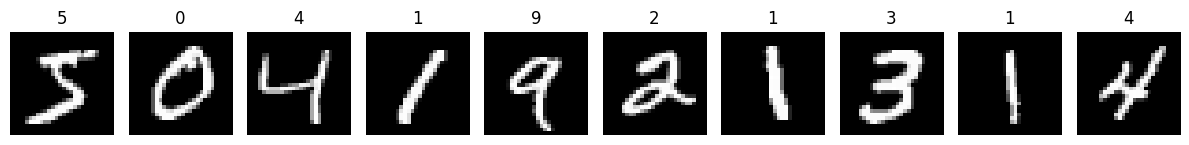

In [28]:
# Display 10 sample images
fig, axes = plt.subplots(1, 10, figsize=(12, 2))

for i in range(10):
    image, label = train_dataset[i]
    image = image.squeeze() * 0.5 + 0.5 # Denormalization
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title(label)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## Network architecture

| Part | Size | Meaning |
|---|---:|---|
| Input | 784 | One value for each pixel |
| Hidden layer | 500 | Learns useful patterns from pixels |
| Output | 10 | One score for each digit (0–9) |

The flow is:

```text
784 inputs → Linear(784, 500) → ReLU → Linear(500, 10) → 10 scores
```

In [29]:

# Define the neural network
class NeuralNet(nn.Module):
    def __init__(self):
        super(NeuralNet, self).__init__()

        # Input layer → Hidden layer 1
        self.l1 = nn.Linear(784, 500)

        # Hidden layer 2
        self.l2 = nn.Linear(500, 500)

        # Hidden layer 3
        self.l3 = nn.Linear(500, 500)

        # Hidden layer 4
        self.l4 = nn.Linear(500, 500)

        # Hidden layer 5
        self.l5 = nn.Linear(500, 500)

        # Output layer
        self.l6 = nn.Linear(500, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.reshape(-1, 28 * 28)

        x = self.relu(self.l1(x))
        x = self.relu(self.l2(x))
        x = self.relu(self.l3(x))
        x = self.relu(self.l4(x))
        x = self.relu(self.l5(x))

        out = self.l6(x)

        return out

model = NeuralNet()


In [30]:
# check input and ouput shapes
images, labels = next(iter(train_loader))
outputs = model(images)

print('Input shape:', images.shape)
print('Output shape:', outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [31]:
# choose the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001, weight_decay=0.0001
)

In [32]:
# Training the model
n_total_steps = len(train_loader)
num_epochs = 3
training_losses = []  # List to dynamically store loss values

for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader): # process every batch in an epoch

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and weight update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i + 1) % 100 == 0:
            training_losses.append(loss.item())
            print(f'Epoch [{epoch + 1}/{num_epochs}], '
                  f'Step [{i + 1}/{n_total_steps}], '
                  f'Loss: {loss.item():.4f}')

Epoch [1/3], Step [100/938], Loss: 0.5723
Epoch [1/3], Step [200/938], Loss: 0.5009
Epoch [1/3], Step [300/938], Loss: 0.1515
Epoch [1/3], Step [400/938], Loss: 0.3966
Epoch [1/3], Step [500/938], Loss: 0.2359
Epoch [1/3], Step [600/938], Loss: 0.0816
Epoch [1/3], Step [700/938], Loss: 0.3002
Epoch [1/3], Step [800/938], Loss: 0.1139
Epoch [1/3], Step [900/938], Loss: 0.2876
Epoch [2/3], Step [100/938], Loss: 0.2950
Epoch [2/3], Step [200/938], Loss: 0.1714
Epoch [2/3], Step [300/938], Loss: 0.0712
Epoch [2/3], Step [400/938], Loss: 0.1964
Epoch [2/3], Step [500/938], Loss: 0.0845
Epoch [2/3], Step [600/938], Loss: 0.2791
Epoch [2/3], Step [700/938], Loss: 0.2542
Epoch [2/3], Step [800/938], Loss: 0.1817
Epoch [2/3], Step [900/938], Loss: 0.1230
Epoch [3/3], Step [100/938], Loss: 0.2503
Epoch [3/3], Step [200/938], Loss: 0.1214
Epoch [3/3], Step [300/938], Loss: 0.0329
Epoch [3/3], Step [400/938], Loss: 0.1950
Epoch [3/3], Step [500/938], Loss: 0.3655
Epoch [3/3], Step [600/938], Loss:

### What happens during one training step?

| Code | Meaning |
|---|---|
| `outputs = model(images)` | The network makes predictions. |
| `criterion(outputs, labels)` | The loss measures prediction error. |
| `optimizer.zero_grad()` | Old gradients are cleared. |
| `loss.backward()` | Gradients are calculated. |
| `optimizer.step()` | Weights are updated. |

The model repeats these steps for every batch and for each epoch.

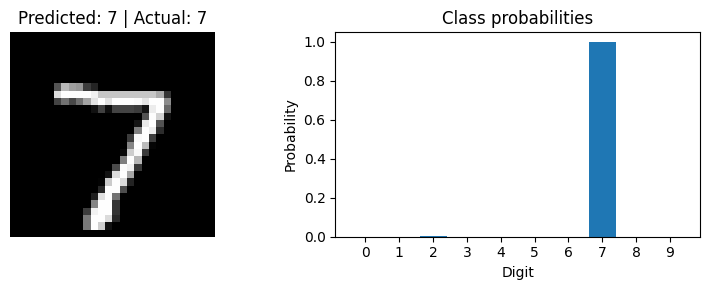

In [33]:
# View one prediction and its probabilities using Softmax
images, labels = next(iter(test_loader))
image = images[0]

with torch.no_grad():
    output = model(image)
    probabilities = torch.softmax(output, dim=1)

probabilities = probabilities.squeeze().numpy()
predicted = probabilities.argmax()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

# Reverse normalization for display
ax1.imshow(image.squeeze() * 0.5 + 0.5, cmap='gray')
ax1.set_title(f'Predicted: {predicted} | Actual: {labels[0].item()}')
ax1.axis('off')

ax2.bar(np.arange(10), probabilities)
ax2.set_xticks(np.arange(10))
ax2.set_xlabel('Digit')
ax2.set_ylabel('Probability')
ax2.set_title('Class probabilities')

plt.tight_layout()
plt.show()

In [34]:
# Evaulating the model
model.eval()
n_correct = 0
n_samples = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.reshape(-1, 28 * 28)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        n_samples += labels.size(0)
        n_correct += (predicted == labels).sum().item()

accuracy =  n_correct / n_samples * 100.0
print(f'Correct predictions:{n_correct}')
print(f'Total Test Samples: {n_samples}')
print(f'Accuracy: {accuracy:.2f}%')

Correct predictions:9652
Total Test Samples: 10000
Accuracy: 96.52%


## 15. Experiments

### Experiment A — Change the hidden layer size

### Experiment B — Compare Adam with SGD

### Experiment C — Add weight decay

```python
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001, weight_decay=0.0001
)
```

Compare the test accuracy with the baseline.

NOTE: Keep the dataset, batch size, and number of epochs the same when comparing experiments.

  Experiments Results

  with SGD Accuracy=85.74%

  with weight decay Accuracy=96.48%

  with 5 hidden layers Accuracy=96.52%*italicized text*


## Additional resources

- [PyTorch — Learn the Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)
- [PyTorch — Defining a Neural Network](https://docs.pytorch.org/tutorials/recipes/recipes/defining_a_neural_network.html)
- [Torchvision — MNIST dataset](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)
- [Deep Learning Specialization](https://www.deeplearning.ai/specializations/deep-learning)
- [PyTorch — Optimization Loop](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
